In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns


cleaned_folder = "cleaned_data"

date = pd.read_csv(
    os.path.join(cleaned_folder, "dim_date_cleaned.csv"),
    parse_dates=["full_date"]
)

product = pd.read_csv(
    os.path.join(cleaned_folder, "dim_product_cleaned.csv"),
    parse_dates=["launch_date"]
)

store = pd.read_csv(
    os.path.join(cleaned_folder, "dim_store_reviewed.csv")
)

f_sales = pd.read_csv(
    os.path.join(cleaned_folder, "fact_daily_sales_reviewed.csv")
)

fact = pd.read_csv(
    os.path.join(cleaned_folder, "fact_store_monthly_profitability_reviewed.csv")
)

In [2]:
print(date.shape, product.shape, store.shape, f_sales.shape, fact.shape)

(730, 11) (40, 10) (60, 13) (10000, 19) (1440, 21)


In [3]:
opened = store.groupby("opening_year").size()
opened #how many stores opened in what years? 

opening_year
2010     3
2011     2
2012     2
2013     5
2014     4
2015     5
2016     5
2017     8
2018     4
2019     2
2020     3
2021     5
2022     2
2023    10
dtype: int64

In [4]:
sd = f_sales.merge(date[["date_id", "year"]], on="date_id", how="left", validate="many_to_one")
sd.shape # date_id and year, from the date table merged with sales 
print(len(f_sales), len(sd)) 
sd.head(5)

10000 10000


,daily_sale_id,store_id,date_id,product_id,total_revenue_gbp,total_transactions,avg_transaction_value_gbp,loyalty_transactions,loyalty_redemption_cost_gbp,footfall,espresso_revenue_gbp,filter_revenue_gbp,food_revenue_gbp,retail_beans_revenue_gbp,daily_gross_profit_gbp,staff_count,total_staff_hours,shift_pattern,avg_dwell_time_minutes,year
0,1,19,393,28,1513.26,192,7.88,96,50.60,201,689.04,131.85,667.12,25.25,784.97,2,11.6,Early-Only,19.7,2024
1,2,29,347,6,1670.85,223,7.49,62,31.83,385,822.54,194.59,544.81,108.91,1063.34,7,51.9,Full-Day,15.8,2023
2,3,14,180,13,1731.65,244,7.10,37,9.46,417,905.11,319.81,464.47,42.26,1199.45,4,21.0,Split-Shift,17.7,2023
3,4,5,727,18,2176.07,326,6.68,74,53.60,328,1260.84,278.50,491.32,145.41,1235.71,8,57.7,Split-Shift,18.5,2024
4,5,47,240,4,1363.39,199,6.85,92,11.12,211,855.07,196.48,279.48,32.36,697.98,4,31.5,Full-Day,20.0,2023


In [5]:
sd.groupby("year")["staff_count"].mean()
#how many staff per record, on average, in each year

year
2023    5.501489
2024    5.564981
Name: staff_count, dtype: float64

In [6]:
store["staff_headcount"].sum() # combined headcount across all stores

np.int64(700)

In [7]:
f_sales["staff_count"].sum() # total staff-shifts across all daily rows

np.int64(55330)

In [8]:
rents = store.set_index("store_name")[["monthly_rent_gbp", "monthly_staffing_cost_gbp"]]
rents.sort_index().head(5)

,monthly_rent_gbp,monthly_staffing_cost_gbp
store_name,,
Sunrise Coffee Aberdeen Express,4122.34,21109.35
Sunrise Coffee Bath Hub,7665.31,22709.65
Sunrise Coffee Belfast Yard,4114.46,15210.30
Sunrise Coffee Birmingham Roastery,3699.71,24316.37
Sunrise Coffee Bradford Brew Bar,5518.28,21427.18


In [9]:
rents["monthly_rent_gbp"].idxmax()  #store with the highest rent

'Sunrise Coffee West London Quarter'

In [10]:
rents["monthly_rent_gbp"].idxmin()  #store with the lowest rent

'Sunrise Coffee Newport House'

In [11]:
rents["monthly_staffing_cost_gbp"].idxmax()  # store with the highest staffing cost

'Sunrise Coffee South London Corner'

In [12]:
rents["monthly_staffing_cost_gbp"].idxmin()  # store with the lowest staffing cost

'Sunrise Coffee Coventry Roastery'

In [13]:
store.groupby("store_status").agg(shops=("store_id", "size"),avg_staffing_cost=("monthly_staffing_cost_gbp", "mean"))

,shops,avg_staffing_cost
store_status,,
Active,57,19234.722105
Refurbishing,1,19758.550000
Temporarily-Closed,2,22610.085000


In [14]:
store.loc[store["loyalty_adoption_rate"].idxmax(), ["store_name", "loyalty_adoption_rate"]]

store_name               Sunrise Coffee Cheltenham Quarter
loyalty_adoption_rate                                0.585
Name: 23, dtype: object

In [15]:
store.loc[store["loyalty_adoption_rate"].idxmin(), ["store_name", "loyalty_adoption_rate"]]

store_name               Sunrise Coffee Newport House
loyalty_adoption_rate                           0.057
Name: 50, dtype: object

In [16]:
date["month_id"] = (date["year"].astype(str)+ "-"+ date["month_number"].astype(str).str.zfill(2))
# creating month_id column

In [17]:
sale_date = f_sales.merge(date[["date_id", "month_id"]],on="date_id",how="left")
print(len(f_sales), len(sale_date))
sale_date.head(5) # added month_id to sales(fact table)

10000 10000


,daily_sale_id,store_id,date_id,product_id,total_revenue_gbp,total_transactions,avg_transaction_value_gbp,loyalty_transactions,loyalty_redemption_cost_gbp,footfall,espresso_revenue_gbp,filter_revenue_gbp,food_revenue_gbp,retail_beans_revenue_gbp,daily_gross_profit_gbp,staff_count,total_staff_hours,shift_pattern,avg_dwell_time_minutes,month_id
0,1,19,393,28,1513.26,192,7.88,96,50.60,201,689.04,131.85,667.12,25.25,784.97,2,11.6,Early-Only,19.7,2024-01
1,2,29,347,6,1670.85,223,7.49,62,31.83,385,822.54,194.59,544.81,108.91,1063.34,7,51.9,Full-Day,15.8,2023-12
2,3,14,180,13,1731.65,244,7.10,37,9.46,417,905.11,319.81,464.47,42.26,1199.45,4,21.0,Split-Shift,17.7,2023-06
3,4,5,727,18,2176.07,326,6.68,74,53.60,328,1260.84,278.50,491.32,145.41,1235.71,8,57.7,Split-Shift,18.5,2024-12
4,5,47,240,4,1363.39,199,6.85,92,11.12,211,855.07,196.48,279.48,32.36,697.98,4,31.5,Full-Day,20.0,2023-08


In [18]:
by_month = sale_date.groupby(["store_id", "month_id"],as_index=False).agg(
    sample_monthly_revenue=("total_revenue_gbp", "sum"),
    average_footfall=("footfall", "mean"),
    daily_record_count=("daily_sale_id", "size"))
by_month.head(5)
#Store-month summary of the daily records.

,store_id,month_id,sample_monthly_revenue,average_footfall,daily_record_count
0,1,2023-01,14754.18,292.750000,8
1,1,2023-02,16970.44,297.333333,9
2,1,2023-03,16051.75,303.555556,9
3,1,2023-04,14933.25,337.625000,8
4,1,2023-05,24134.22,334.750000,12


In [19]:
by_month.groupby("store_id")["average_footfall"].max().head(10)

store_id
1     421.500000
2     485.142857
3     476.545455
4     617.000000
5     492.571429
6     485.571429
7     454.125000
8     497.000000
9     622.750000
10    416.800000
Name: average_footfall, dtype: float64

In [20]:
by_month.groupby("store_id")["average_footfall"].min().head(10)

store_id
1     256.571429
2     247.000000
3     249.500000
4     287.166667
5     264.200000
6     295.666667
7     157.000000
8     286.000000
9     370.250000
10    176.000000
Name: average_footfall, dtype: float64

In [21]:
by_month.groupby(["store_id", "month_id"], as_index=False)["sample_monthly_revenue"].min().head(10)

,store_id,month_id,sample_monthly_revenue
0,1,2023-01,14754.18
1,1,2023-02,16970.44
2,1,2023-03,16051.75
3,1,2023-04,14933.25
4,1,2023-05,24134.22
5,1,2023-06,19156.02
6,1,2023-07,4666.42
7,1,2023-08,1769.14
8,1,2023-09,11056.60
9,1,2023-10,5301.14


In [22]:
by_month.groupby(["store_id", "month_id"], as_index=False) ["sample_monthly_revenue"].max()

,store_id,month_id,sample_monthly_revenue
0,1,2023-01,14754.18
1,1,2023-02,16970.44
2,1,2023-03,16051.75
3,1,2023-04,14933.25
4,1,2023-05,24134.22
...,...,...,...
1433,60,2024-08,15066.37
1434,60,2024-09,25594.13
1435,60,2024-10,11434.61
1436,60,2024-11,17008.62


In [23]:
m = fact.merge(by_month,on=["store_id", "month_id"],how="left",validate="one_to_one")
print(len(fact), len(m))   
m.head(5)
#Monthly profit + sales summary, one row per store-month.

1440 1440


,monthly_profit_id,store_id,date_id,month_id,total_monthly_revenue_gbp,total_monthly_cogs_gbp,monthly_rent_gbp,monthly_staffing_cost_gbp,loyalty_redemption_cost_gbp,net_profit_gbp,...,non_member_spend_gbp,revenue_per_sqft_gbp,peak_hour_transactions,dead_hour_transactions,avg_dwell_time_minutes,rent_band,profitability_status,sample_monthly_revenue,average_footfall,daily_record_count
0,1,1,1,2023-01,43122.38,18960.29,5668.39,18650.39,1265.95,-1422.64,...,32039.93,34.61,2132,232,16.6,Medium,Break-Even,14754.18,292.750000,8.0
1,2,1,32,2023-02,85280.28,32937.97,6144.28,15500.71,1205.06,29492.26,...,56881.95,68.44,1948,419,21.9,Medium,Highly-Profitable,16970.44,297.333333,9.0
2,3,1,60,2023-03,77887.37,32295.39,5553.55,20051.35,1790.04,18197.04,...,53586.51,62.51,1739,406,21.9,Medium,Profitable,16051.75,303.555556,9.0
3,4,1,91,2023-04,68856.94,24246.13,6212.06,16554.04,1353.44,20491.27,...,45239.01,55.26,1974,272,22.2,Medium,Highly-Profitable,14933.25,337.625000,8.0
4,5,1,121,2023-05,74488.85,29922.81,5732.17,19102.84,798.93,18932.10,...,50428.95,59.78,1512,526,40.8,Medium,Profitable,24134.22,334.750000,12.0


In [24]:
m.info()

<class 'pandas.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 24 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   monthly_profit_id            1440 non-null   int64  
 1   store_id                     1440 non-null   int64  
 2   date_id                      1440 non-null   int64  
 3   month_id                     1440 non-null   str    
 4   total_monthly_revenue_gbp    1440 non-null   float64
 5   total_monthly_cogs_gbp       1440 non-null   float64
 6   monthly_rent_gbp             1440 non-null   float64
 7   monthly_staffing_cost_gbp    1440 non-null   float64
 8   loyalty_redemption_cost_gbp  1440 non-null   float64
 9   net_profit_gbp               1440 non-null   float64
 10  net_profit_margin_pct        1440 non-null   float64
 11  avg_daily_footfall           1440 non-null   float64
 12  loyalty_member_revenue_pct   1440 non-null   float64
 13  loyalty_member_spend_gbp     

In [25]:
fact.info()

<class 'pandas.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 21 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   monthly_profit_id            1440 non-null   int64  
 1   store_id                     1440 non-null   int64  
 2   date_id                      1440 non-null   int64  
 3   month_id                     1440 non-null   str    
 4   total_monthly_revenue_gbp    1440 non-null   float64
 5   total_monthly_cogs_gbp       1440 non-null   float64
 6   monthly_rent_gbp             1440 non-null   float64
 7   monthly_staffing_cost_gbp    1440 non-null   float64
 8   loyalty_redemption_cost_gbp  1440 non-null   float64
 9   net_profit_gbp               1440 non-null   float64
 10  net_profit_margin_pct        1440 non-null   float64
 11  avg_daily_footfall           1440 non-null   float64
 12  loyalty_member_revenue_pct   1440 non-null   float64
 13  loyalty_member_spend_gbp     

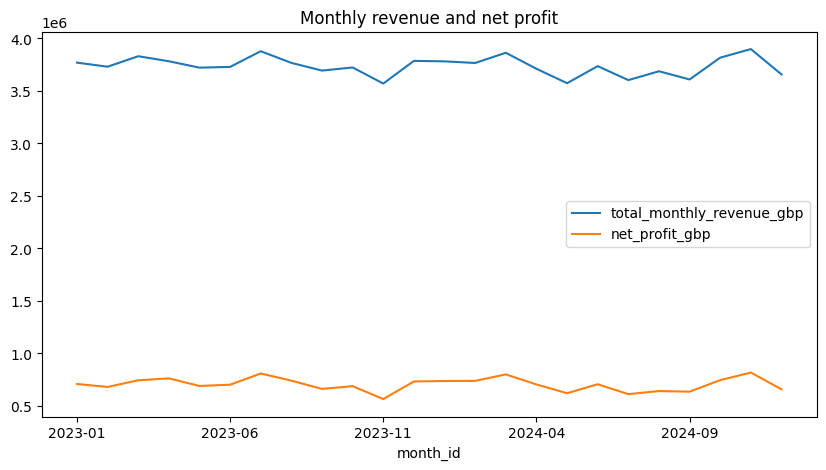

In [26]:
trend = m.groupby("month_id")[["total_monthly_revenue_gbp", "net_profit_gbp"]].sum()
trend.plot(figsize=(10, 5), title="Monthly revenue and net profit")
plt.show()
#Is the business growing, and does it have seasons?

In [27]:
m["margin"] = m["net_profit_gbp"] / m["total_monthly_revenue_gbp"]
by_store = m.groupby("store_id").agg(total_profit=("net_profit_gbp", "sum"),avg_margin=("margin", "mean"))
by_store.nsmallest(5, "total_profit")

,total_profit,avg_margin
store_id,,
32,-50494.58,-0.106530
53,42807.39,-0.033572
19,66552.21,-0.124478
43,74178.61,0.035797
5,131422.52,0.061489


In [28]:
by_store.nlargest(5, "total_profit")

,total_profit,avg_margin
store_id,,
30,574223.29,0.356349
51,471673.72,0.286446
6,463628.43,0.272421
56,451906.07,0.255333
10,422207.82,0.276858


In [29]:
m["profitability_status"].value_counts()
#Which stores earn the most, and which lose money?

profitability_status
Profitable           581
Break-Even           368
Highly-Profitable    327
Loss-Making          147
Structural-Loss       17
Name: count, dtype: int64

In [30]:
m["rent_pct"] = m["monthly_rent_gbp"] / m["total_monthly_revenue_gbp"]
m["staff_pct"] = m["monthly_staffing_cost_gbp"] / m["total_monthly_revenue_gbp"]
m["cogs_pct"] = m["total_monthly_cogs_gbp"] / m["total_monthly_revenue_gbp"]
m[["cogs_pct", "staff_pct", "rent_pct"]].describe()

,cogs_pct,staff_pct,rent_pct
count,1440.000000,1440.000000,1440.000000
mean,0.379216,0.340316,0.113078
std,0.034098,0.170410,0.068701
min,0.320135,0.105180,0.020691
25%,0.349170,0.244215,0.069237
50%,0.378488,0.307933,0.095138
75%,0.407927,0.393734,0.141371
max,0.439923,2.828600,1.277228


In [31]:
m.groupby("rent_band")[["net_profit_gbp", "margin", "revenue_per_sqft_gbp"]].mean()

,net_profit_gbp,margin,revenue_per_sqft_gbp
rent_band,,,
High,6682.366490,0.052464,47.126623
Low,13304.275148,0.171204,54.070436
Medium,11518.319930,0.145898,52.126201


In [32]:
# Which products have a launch date, and what status are they?
product[product.launch_date.notna()][["product_name", "product_category", "product_status", "launch_date"]]

,product_name,product_category,product_status,launch_date
10,Pumpkin Spice Latte,Espresso-Drinks,Seasonal,2023-09-01
11,Festive Latte,Espresso-Drinks,Seasonal,2023-01-01
25,Christmas Mince Pie,Food,Seasonal,2023-09-01
33,Christmas Blend 250g,Retail-Beans,Seasonal,2023-09-01


In [33]:
NAME = "product_name"
CATEGORY = "product_category"

In [34]:
sp = sale_date.merge(product[["product_id", NAME, CATEGORY]], on="product_id", how="left", validate="many_to_one")
sp["year"] = sp["month_id"].str[:4]     # first 4 letters of "2023-01" = the year
print(len(sale_date), len(sp))           # must be equal
print(sp[NAME].isna().sum())             # receipts with no product found, want 0

10000 10000
0


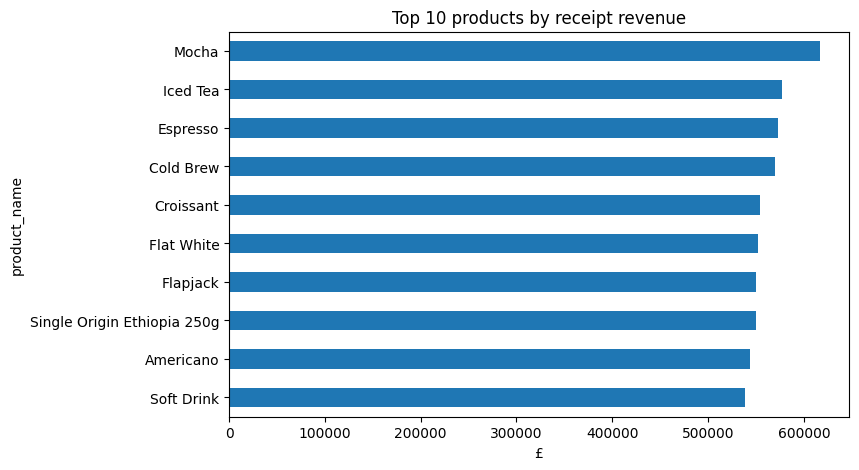

In [35]:
top = sp.groupby(NAME)["total_revenue_gbp"].sum().nlargest(10)
top.sort_values().plot.barh(figsize=(8, 5), title="Top 10 products by receipt revenue")
plt.xlabel("£"); plt.show()

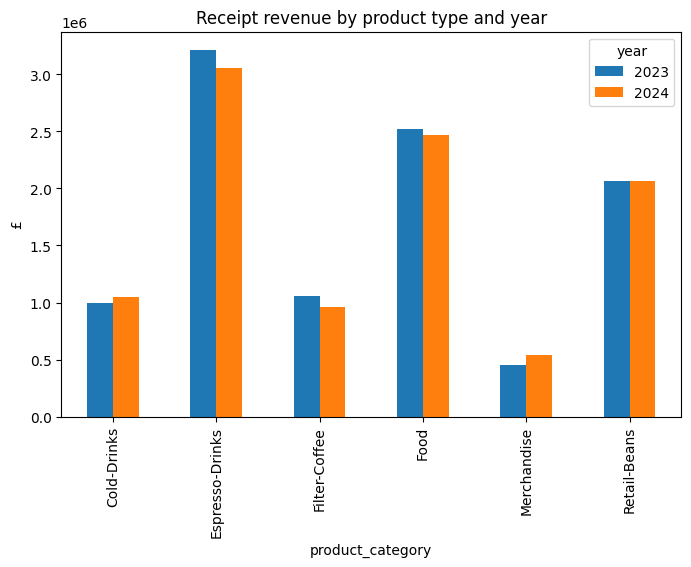

In [36]:
cat = sp.groupby([CATEGORY, "year"])["total_revenue_gbp"].sum().unstack()
cat.plot.bar(figsize=(8, 5), title="Receipt revenue by product type and year")
plt.ylabel("£"); plt.show()

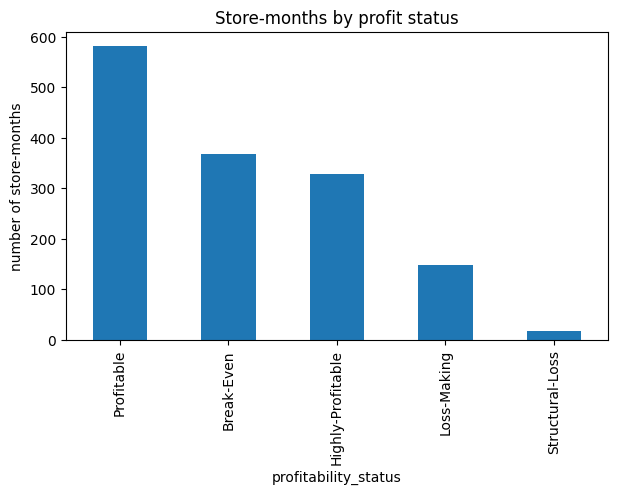

In [37]:
m["profitability_status"].value_counts().plot.bar(figsize=(7, 4), title="Store-months by profit status")
plt.ylabel("number of store-months"); plt.show()

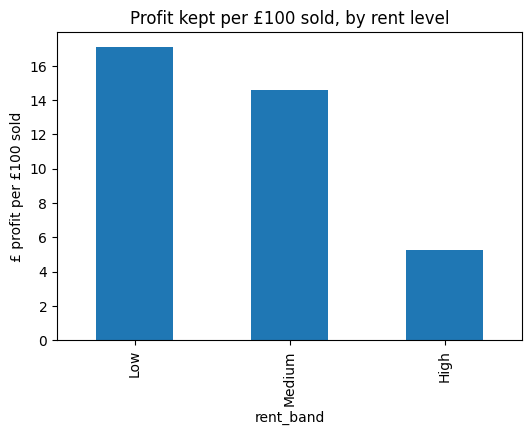

In [38]:
m["margin"] = m["net_profit_gbp"] / m["total_monthly_revenue_gbp"]
(m.groupby("rent_band")["margin"].mean() * 100).reindex(["Low", "Medium", "High"]).plot.bar(
    figsize=(6, 4), title="Profit kept per £100 sold, by rent level")
plt.ylabel("£ profit per £100 sold"); plt.show()

1440 1440


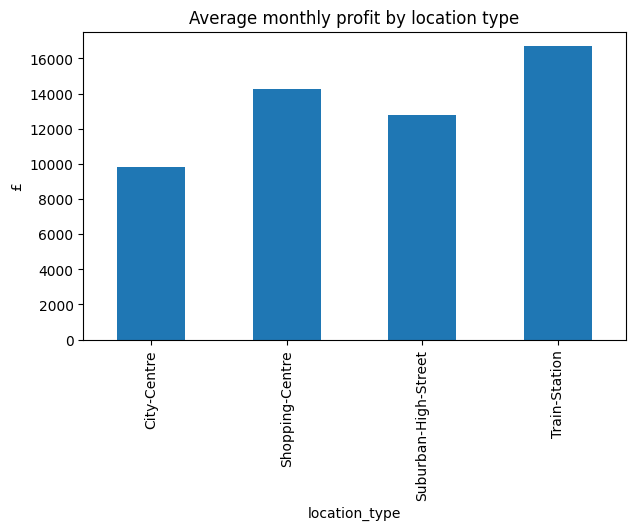

In [39]:
ms = m.merge(store[["store_id", "location_type"]], on="store_id", how="left", validate="many_to_one")
print(len(m), len(ms))                   
ms.groupby("location_type")["net_profit_gbp"].mean().plot.bar(figsize=(7, 4), title="Average monthly profit by location type")
plt.ylabel("£"); plt.show()

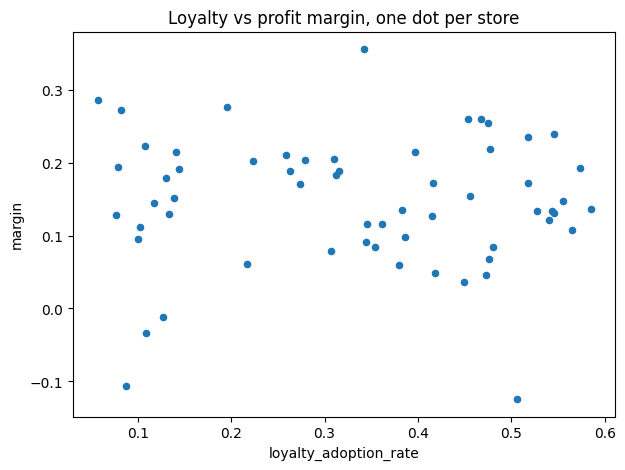

In [40]:
st = m.groupby("store_id")["margin"].mean().reset_index()
st = st.merge(store[["store_id", "loyalty_adoption_rate"]], on="store_id", how="left", validate="one_to_one")
st.plot.scatter(x="loyalty_adoption_rate", y="margin", figsize=(7, 5), title="Loyalty vs profit margin, one dot per store")
plt.show()

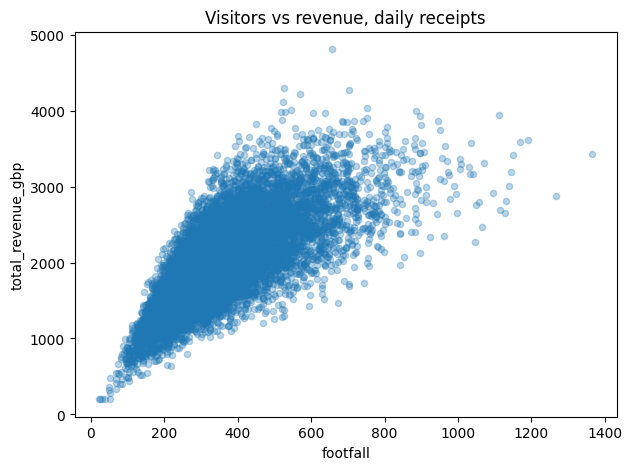

In [41]:
sale_date.plot.scatter(x="footfall", y="total_revenue_gbp", alpha=0.3, figsize=(7, 5), title="Visitors vs revenue, daily receipts")
plt.show()

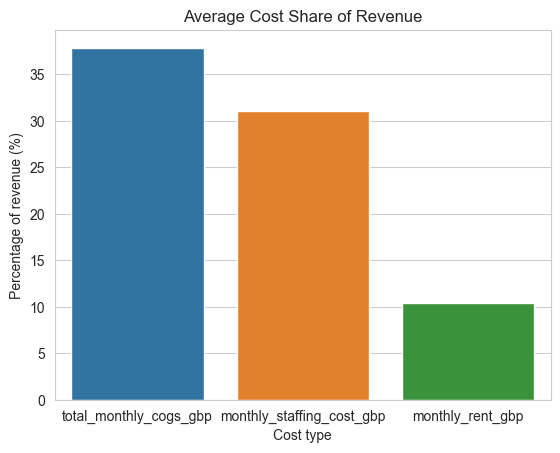

In [51]:
cost = fact.groupby('store_id')[
    ['total_monthly_cogs_gbp', 'monthly_staffing_cost_gbp', 'monthly_rent_gbp', 'total_monthly_revenue_gbp']
].mean()

cost_pct = cost[['total_monthly_cogs_gbp', 'monthly_staffing_cost_gbp', 'monthly_rent_gbp']].div(
    cost['total_monthly_revenue_gbp'], axis=0
) * 100

sns.barplot(data=cost_pct, errorbar=None)
plt.title('Average Cost Share of Revenue')
plt.ylabel('Percentage of revenue (%)')
plt.xlabel('Cost type')
plt.show()

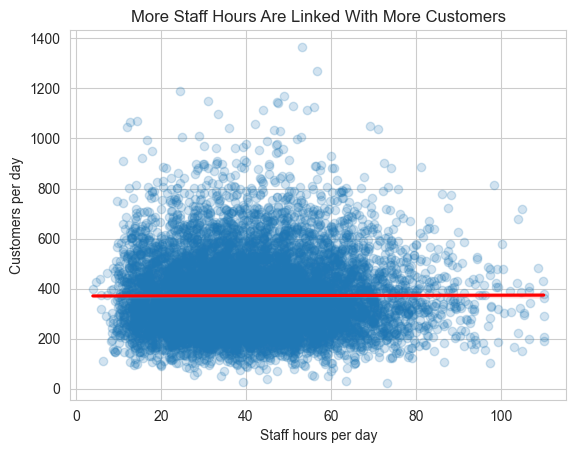

In [54]:
sns.regplot(data=f_sales, x='total_staff_hours', y='footfall', scatter_kws={'alpha': 0.2}, line_kws={'color': 'red'})

plt.title('More Staff Hours Are Linked With More Customers')
plt.xlabel('Staff hours per day')
plt.ylabel('Customers per day')
plt.show()

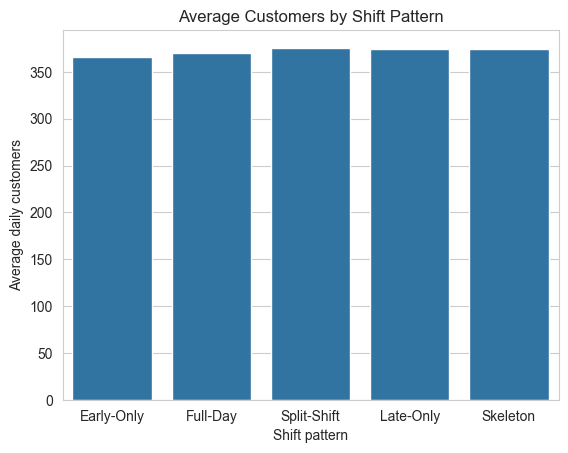

In [56]:
sns.barplot(data=f_sales, x='shift_pattern', y='footfall', estimator='mean', errorbar=None)

plt.title('Average Customers by Shift Pattern')
plt.xlabel('Shift pattern')
plt.ylabel('Average daily customers')
plt.show()

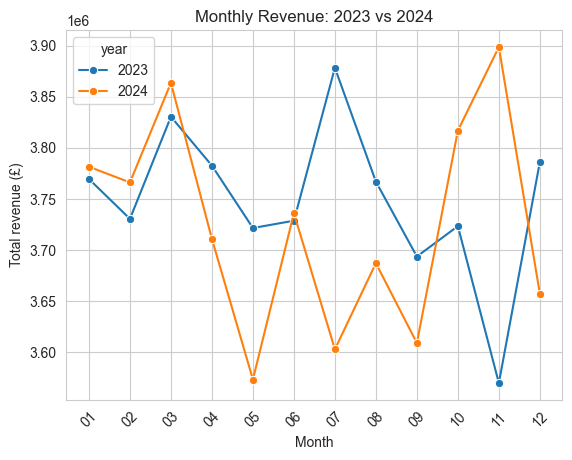

In [57]:
fact['year'] = fact['month_id'].str[:4]
fact['month'] = fact['month_id'].str[5:]

monthly_revenue = fact.groupby(['month', 'year'])['total_monthly_revenue_gbp'].sum().reset_index()

sns.lineplot(data=monthly_revenue, x='month', y='total_monthly_revenue_gbp', hue='year', marker='o')

plt.title('Monthly Revenue: 2023 vs 2024')
plt.xlabel('Month')
plt.ylabel('Total revenue (£)')
plt.xticks(rotation=45)
plt.show()

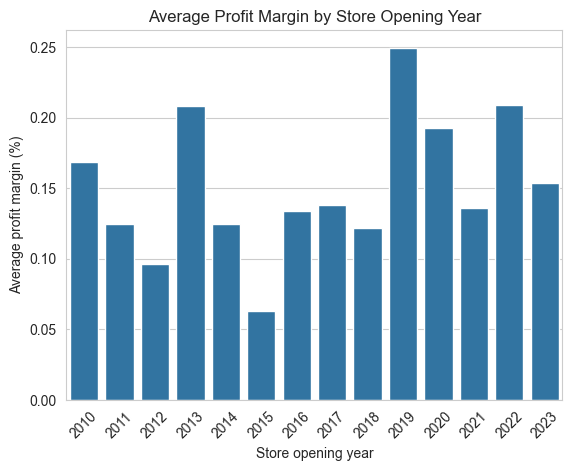

In [58]:
margin_year = fact.merge(store[['store_id', 'opening_year']], on='store_id', how='left')

sns.barplot(data=margin_year, x='opening_year', y='net_profit_margin_pct', estimator='mean', errorbar=None)

plt.title('Average Profit Margin by Store Opening Year')
plt.xlabel('Store opening year')
plt.ylabel('Average profit margin (%)')
plt.xticks(rotation=45)
plt.show()

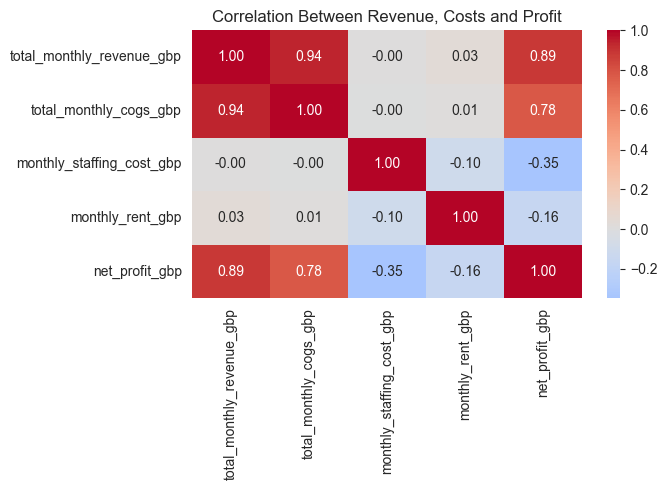

In [62]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    fact[['total_monthly_revenue_gbp', 'total_monthly_cogs_gbp', 'monthly_staffing_cost_gbp', 'monthly_rent_gbp', 'net_profit_gbp']].corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Between Revenue, Costs and Profit')
plt.tight_layout()
plt.show()